In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
os.environ["KERAS_BACKEND"] = "torch"
import torch
import keras

## Constants - Base setup values
Size of image defined by max_dim.  Number of colors are defined by max_color.

In [2]:
max_dim = 30
max_color = 9
os.environ["MAX_DIM"] = str(max_dim)
os.environ["MAX_COLOR"] = str(max_color)
np.random.seed(230928)

In [3]:
# from train_squares import generate_images
# or
def generate_images(random_background, number_boxes, box_size, space):
  
    def new_box(size):
        box = np.random.randint(max_dim - size, size=(1,4))
        box[0,2] = box[0,0] + size
        box[0,3] = box[0,1] + size
        return box

    def no_overlap(boxes, box2, space):
    # assume box1 is same size or bigger than box2.  No overlap if no point of box2
    # is inside box1.  Uses space to grow size of box1.
    # Generalize to box1 being an array of boxes.
        for box1 in boxes:
            if   box1[0]-space < box2[0] and box1[2]+space > box2[0] and box1[1]-space < box2[1] and box1[3]+space > box2[1]:
                return False
            elif box1[0]-space < box2[0] and box1[2]+space > box2[0] and box1[1]-space < box2[3] and box1[3]+space > box2[3]:
                return False
            elif box1[0]-space < box2[2] and box1[2]+space > box2[2] and box1[1]-space < box2[1] and box1[3]+space > box2[1]:
                return False
            elif box1[0]-space < box2[2] and box1[2]+space > box2[2] and box1[1]-space < box2[3] and box1[3]+space > box2[3]:
                return False
        return True

    def generate_boxes(number_boxes=4, box_size=8, space=1):
        box_array = new_box(box_size)
        size = box_size//2
        for i in range(number_boxes-1):
            next_box = new_box(size)
            count = 0
            while not no_overlap(box_array, next_box[0], space):
                if count < 5:
                    count += 1
                else:
                    size = size//2
                    if size < 1:
                        size = 1
                    count = 0
                next_box = new_box(size)
            box_array = np.append(box_array, next_box, axis=0)
        return box_array
  
    if random_background:
        background = np.random.randint(max_color)
        color_array = np.random.randint(max_color, size=(1,number_boxes))
        for box in range(number_boxes):
            if color_array[0,box] == background:
                if color_array[0,box] == 0:
                    color_array[0,box] = 1
                else:
                    color_array[0,box] = background - 1
    else:
        background = 0
        color_array = np.random.randint(1, high=max_color+1, size=(1,number_boxes))
        
    box_array = np.concatenate((generate_boxes(number_boxes, box_size, space), color_array.T), axis=1)
    a = np.ones((max_dim, max_dim))
    a = a * background
    for box in box_array:
        a[box[0]:box[2], box[1]:box[3]] = box[4]
    b = np.zeros((max_dim,max_dim))
    b[box_array[0,0]:box_array[0,2], box_array[0,1]:box_array[0,3]] = 1
    return (a,b)

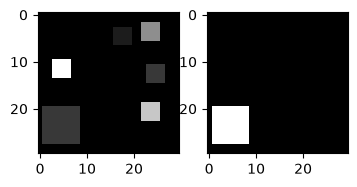

In [4]:
a, b = generate_images(False, 6, 8, 1)
figure = plt.figure(figsize=(4,2))
col, row = 2, 1
figure.add_subplot(row, col, 1)
plt.imshow(a,cmap='gray')
figure.add_subplot(row, col, 2)
plt.imshow(b,cmap='gray')
plt.show()

In [5]:
def display(array1, array2):
    """Displays ten random images from each array."""
    n = 10
    images1 = array1[0:n, :]
    images2 = array2[0:n, :]

    plt.figure(figsize=(20, 4))
    for i, (image1, image2) in enumerate(zip(images1, images2)):
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(image1)
        plt.gray()
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)

        ax = plt.subplot(2, n, i + 1 + n)
        plt.imshow(image2)
        plt.gray()
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)

    plt.show()

In [6]:
def expand(array):
    b = np.zeros((max_dim, max_dim, max_color+1), np.float16) 
    for x in range(max_dim):
        for y in range(max_dim):
            b[x][y][int(array[x][y])] = 1.0
    return b

c = expand(a)
print(c.shape)

(30, 30, 10)


In [7]:
def one_hundred(list_in, list_out, random_background, number_boxes, box_size, space):
    for _ in range(100):
        a, b = generate_images(random_background, number_boxes, box_size, space)
        list_in.append(expand(a))
        list_out.append(b)
    return list_in, list_out

In [18]:
def build_training():
    train_in_list, train_out_list = list(), list()
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 8, 2, 2)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 15, 2, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 7, 3, 2)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 12, 3, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 10, 4, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 15, 4, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 5, 5, 2)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 11, 5, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 5, 6, 2)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 10, 6, 0)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 15, 6, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 5, 7, 2)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 15, 7, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 5, 8, 2)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 15, 8, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 5, 9, 2)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 15, 9, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 5, 11, 2)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 15, 11, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 15, 11, 0)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 11, 12, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 9, 13, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 8, 14, 1)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 5, 15, 2)
    train_in_list, train_out_list = one_hundred(train_in_list, train_out_list, True, 15, 16, 1)
    return train_in_list, train_out_list
    
train_in_list, train_out_list = build_training()
train_in = np.array(train_in_list)
train_out = np.array(train_out_list)
print(train_in.shape)
print(train_out.shape)

(2500, 30, 30, 10)
(2500, 30, 30)


In [24]:
input = keras.layers.Input(shape=(max_dim, max_dim, max_color+1))
x = keras.layers.Conv2D(16, (2, 2), activation="relu", padding="valid")(input)            # 29,29,16
x = keras.layers.SeparableConv2D(32, (2, 2), activation="relu", padding="valid")(x)       # 28,28,32
x = keras.layers.SeparableConv2D(48, (3, 3), activation="relu", padding="valid")(x)          # 26,26,48
x2 = keras.layers.SeparableConv2D(16, (3,3), strides=2, activation='relu', padding="valid")(x)  # 12,12,16
x2 = keras.layers.SeparableConv2D(32, (3,3), strides=2, activation='relu', padding="valid")(x2) # 5,5,32
x2 = keras.layers.SeparableConv2D(48, (3,3), strides=1, activation='relu', padding="valid")(x2) # 3,3,48
x2 = keras.layers.Conv2D(64, (3,3), strides=1, activation="relu", padding="valid")(x2)           # 1,1,64
x2 = keras.layers.Conv2DTranspose(48, (3, 3), strides=1, activation="relu", padding="valid")(x2)  # 3,3,48
x2 = keras.layers.Conv2DTranspose(32, (3, 3), strides=1, activation="relu", padding="valid")(x2)  # 5,5,32
x2 = keras.layers.Conv2DTranspose(32, (3, 3), strides=2, activation="relu", padding="valid")(x2)  # 11,11,32
x2 = keras.layers.Conv2DTranspose(32, (3, 3), strides=2, activation="relu", padding="valid")(x2)  # 23,23,32
x2 = keras.layers.Conv2DTranspose(16, (3, 3), strides=1, activation="relu", padding="valid")(x2)  # 25,25,16
x2 = keras.layers.Conv2DTranspose(16, (2, 2), strides=1, activation="relu", padding="valid")(x2)  # 26,26,16

x3 = keras.layers.Concatenate(axis=-1)([x, x2])
x3 = keras.layers.Conv2D(48, (1, 1), strides=1, activation="relu", padding="valid")(x3)
x3 = keras.layers.Conv2DTranspose(32, (3, 3), strides=1, activation="relu", padding="valid")(x3)
x3 = keras.layers.Conv2DTranspose(32, (2, 2), strides=1, activation="relu", padding="valid")(x3)
x3 = keras.layers.Conv2DTranspose(32, (2, 2), strides=1, activation="relu", padding="valid")(x3)
x3 = keras.layers.Conv2D(1, (1, 1), activation="sigmoid", padding="valid")(x3)

autoencoder = keras.models.Model(input, x3)
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")
autoencoder.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 30, 30,    │          0 │ -                 │
│ (InputLayer)        │ 10)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 29, 29,    │        656 │ input_layer_2[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_10 │ (None, 28, 28,    │        608 │ conv2d_8[0][0]    │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_11 │ (None, 26, 26,    │      1,872 │ separable_conv2d… │
│ (SeparableConv2D)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_12 │ (None, 12, 12,    │      1,216 │ separable_conv2d… │
│ (SeparableConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_13 │ (None, 5, 5, 32)  │        688 │ separable_conv2d… │
│ (SeparableConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_14 │ (None, 3, 3, 48)  │      1,872 │ separable_conv2d… │
│ (SeparableConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 1, 1, 64)  │     27,712 │ separable_conv2d… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_18 │ (None, 3, 3, 48)  │     27,696 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_19 │ (None, 5, 5, 32)  │     13,856 │ conv2d_transpose… │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_20 │ (None, 11, 11,    │      9,248 │ conv2d_transpose… │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_21 │ (None, 23, 23,    │      9,248 │ conv2d_transpose… │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_22 │ (None, 25, 25,    │      4,624 │ conv2d_transpose… │
│ (Conv2DTranspose)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_23 │ (None, 26, 26,    │      1,040 │ conv2d_transpose… │
│ (Conv2DTranspose)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 26, 26,    │          0 │ separable_conv2d… │
│ (Concatenate)       │ 64)               │            │ conv2d_transpose… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 26, 26,    │      3,120 │ concatenate_2[0]… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_24 │ (None, 28, 28,    │     13,856 │ conv2d_10[0][0]   │
│ (Conv2DTranspose)   │ 32)               │            │                 

 Total params: 125,601 (490.63 KB)

 Trainable params: 125,601 (490.63 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
test_in, test_out = list(), list()

for _ in range(10):
    a, b = generate_images(False, 9, 10, 1)
    test_in.append(expand(a))
    test_out.append(b)

test_in = np.array(test_in)
test_out = np.array(test_out)
print(test_in.shape)
print(test_out.shape)

(10, 30, 30, 10)
(10, 30, 30)


In [44]:
autoencoder.fit(
    x=train_in,
    y=train_out,
    epochs=10,
    batch_size=50,
    shuffle=True,
    validation_data=(test_in, test_out),
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0224 - val_loss: 0.1412
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0131 - val_loss: 0.1665
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.0095 - val_loss: 0.1963
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0082 - val_loss: 0.2077
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0068 - val_loss: 0.2334
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0062 - val_loss: 0.2387
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0057 - val_loss: 0.2601
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0047 - val_loss: 0.2717
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0042 - val_loss: 0.2580
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0041 - val_loss: 0.2736


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


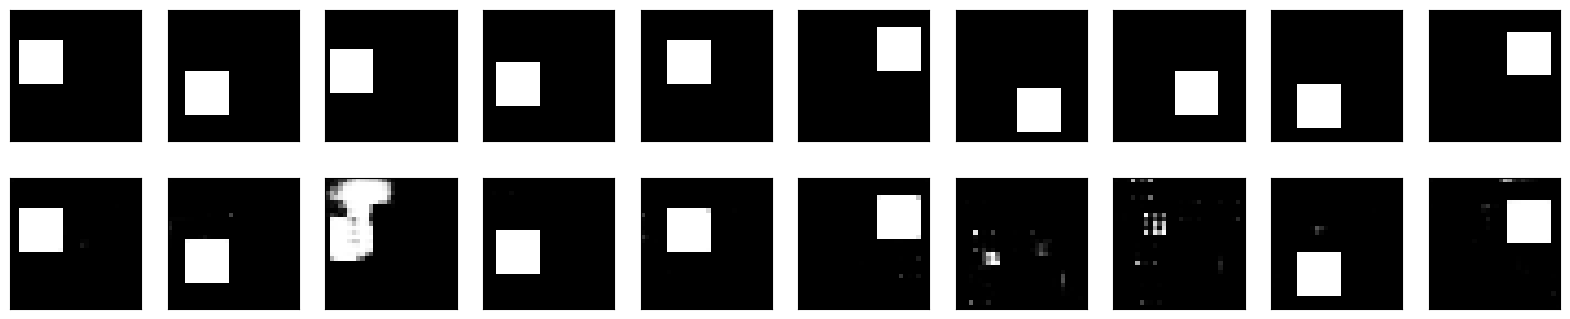

In [45]:
predictions = autoencoder.predict(test_in)
display(test_out, predictions)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0051 - val_loss: 8.5599e-04
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 4.4685e-04 - val_loss: 0.0030
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 1.2118e-04 - val_loss: 0.0016
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 5.3323e-05 - val_loss: 0.0012
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 3.0800e-05 - val_loss: 0.0013
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 2.0073e-05 - val_loss: 0.0013
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 1.3644e-05 - val_loss: 0.0012
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 1.0691e-05 - val_loss: 0.0012
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 8.5114e-06 - val_loss: 0.0011
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 6.9333e-06 - val_loss: 0.0011
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


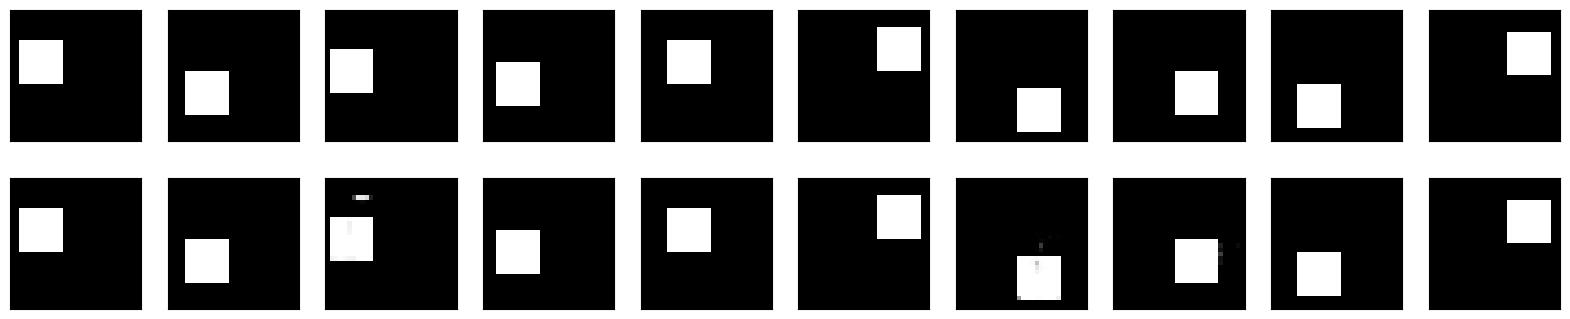

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.0012 - val_loss: 1.4102e-04
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 3.3986e-04 - val_loss: 0.0010
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 2.4500e-04 - val_loss: 1.0099e-04
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 7.8127e-05 - val_loss: 1.4552e-04
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 4.0670e-05 - val_loss: 2.4610e-04
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 2.4993e-05 - val_loss: 2.9913e-04
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 1.5852e-05 - val_loss: 2.8203e-04
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 1.1141e-05 - val_loss: 3.5619e-04
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 8.7149e-06 - val_loss: 3.6255e-04
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 6.8138e-06 - val_loss: 3.8505e-04
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


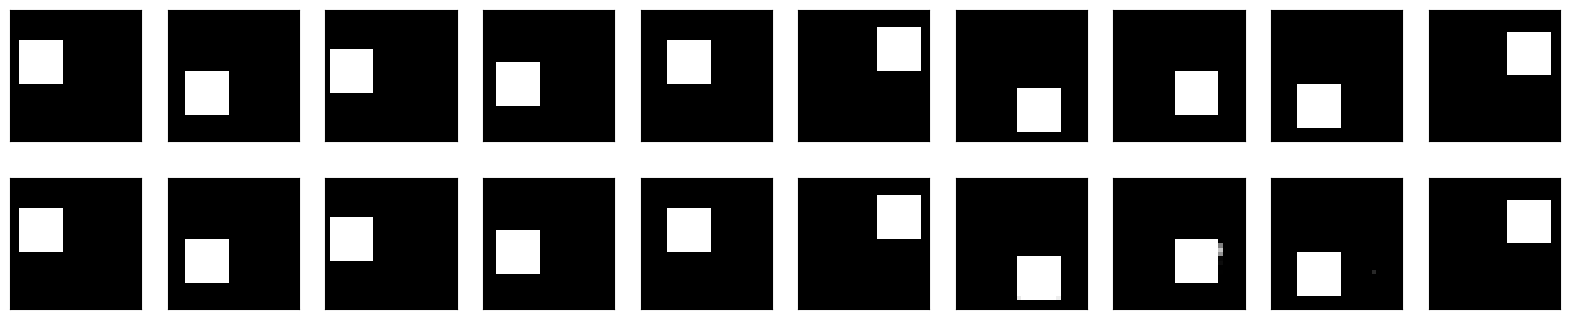

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0019 - val_loss: 0.0029
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 9.8729e-04 - val_loss: 3.1716e-04
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 3.5250e-04 - val_loss: 0.0011
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 1.0352e-04 - val_loss: 7.9406e-04
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 5.9057e-05 - val_loss: 7.1973e-04
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 3.6330e-05 - val_loss: 7.1825e-04
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.8366e-05 - val_loss: 8.8735e-04
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 1.2354e-05 - val_loss: 9.3226e-04
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 9.5844e-06 - val_loss: 9.4612e-04
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 7.5830e-06 - val_loss: 9.4906e-04
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


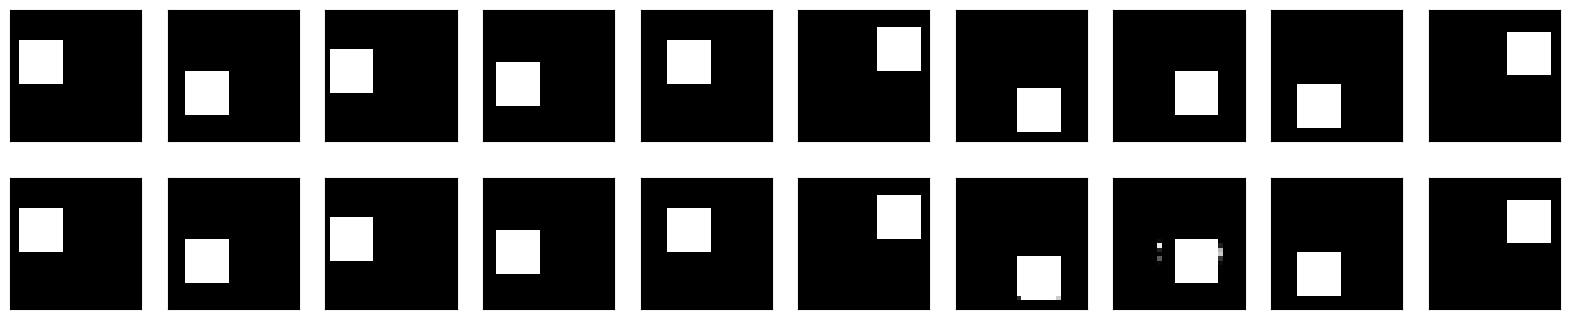

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 6.5332e-04 - val_loss: 0.0028
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 1.5857e-04 - val_loss: 0.0027
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 1.1269e-04 - val_loss: 0.0022
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 4.9568e-05 - val_loss: 0.0031
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 2.0192e-05 - val_loss: 0.0027
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 1.1890e-05 - val_loss: 0.0031
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 7.8129e-06 - val_loss: 0.0032
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 6.0466e-06 - val_loss: 0.0032
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 4.8916e-06 - val_loss: 0.0033
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 4.0929e-06 - val_loss: 0.0034
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


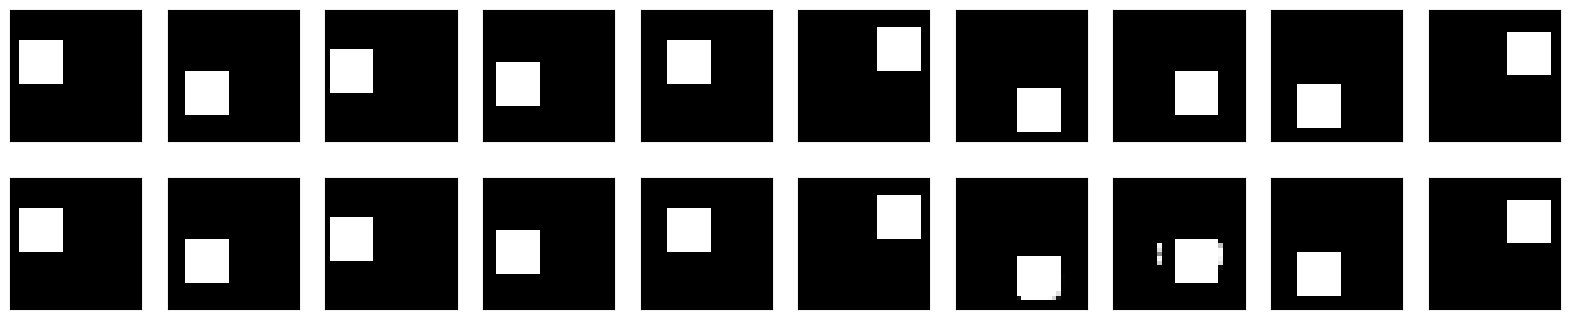

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0011 - val_loss: 0.0020
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 5.6834e-04 - val_loss: 0.0061
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 8.3751e-04 - val_loss: 0.0029
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 1.4548e-04 - val_loss: 4.6665e-04
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 3.3339e-05 - val_loss: 4.0728e-04
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.6317e-05 - val_loss: 3.8567e-04
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 1.1076e-05 - val_loss: 3.0444e-04
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 8.1385e-06 - val_loss: 2.7805e-04
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 6.5123e-06 - val_loss: 2.4260e-04
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 5.3729e-06 - val_loss: 2.2715e-04
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


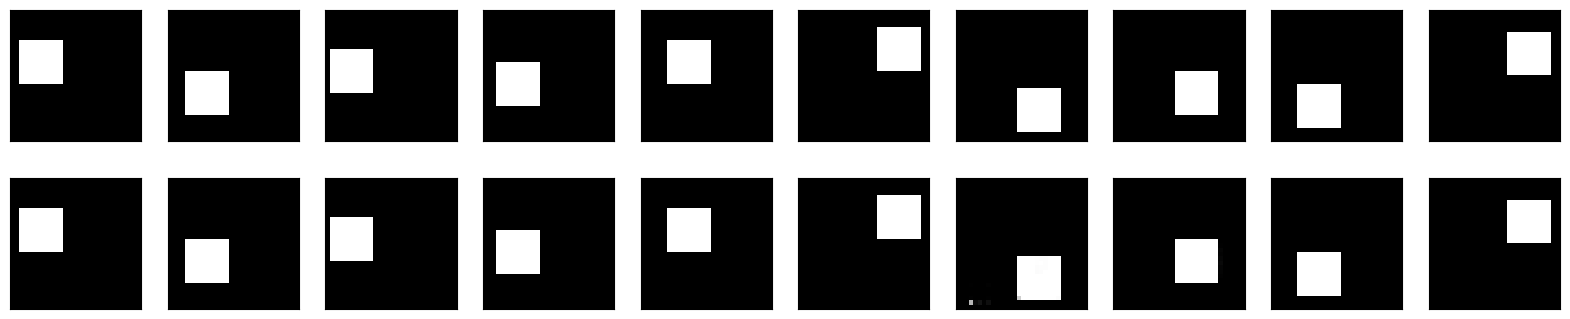

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 7.3272e-04 - val_loss: 0.0011
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 1.5719e-04 - val_loss: 5.9244e-04
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 1.4391e-04 - val_loss: 4.6851e-04
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 6.7273e-05 - val_loss: 7.3138e-04
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 2.9500e-05 - val_loss: 8.6833e-04
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 1.9391e-05 - val_loss: 8.6595e-04
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 1.4127e-05 - val_loss: 0.0011
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 1.1745e-05 - val_loss: 0.0012
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 9.1368e-06 - val_loss: 0.0013
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 8.5059e-06 - val_loss: 0.0014
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


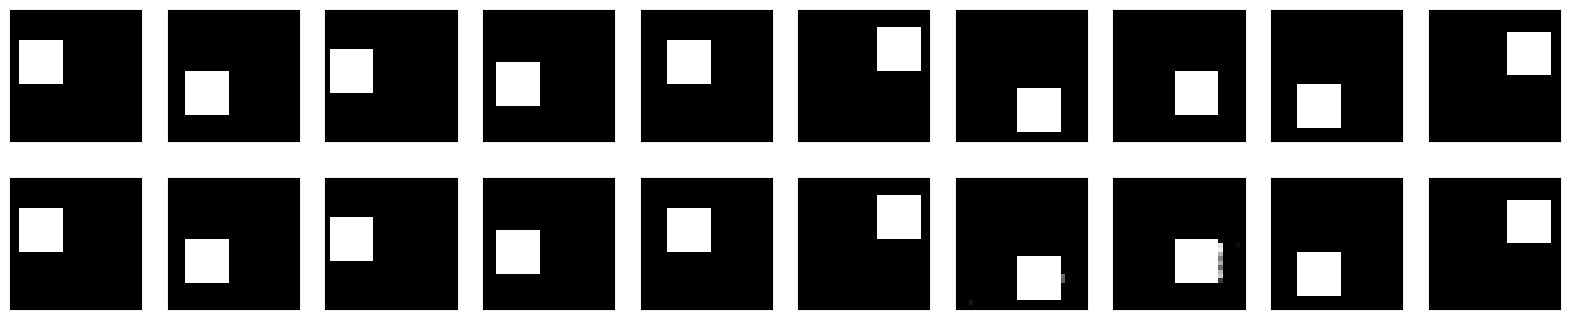

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0016 - val_loss: 0.0129
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 7.6574e-04 - val_loss: 0.1686
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 3.6309e-04 - val_loss: 0.1300
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 1.2984e-04 - val_loss: 0.0184
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 4.2896e-05 - val_loss: 0.0092
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 1.9214e-05 - val_loss: 0.0091
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 1.2208e-05 - val_loss: 0.0093
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 8.4453e-06 - val_loss: 0.0087
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 6.7314e-06 - val_loss: 0.0086
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 5.6492e-06 - val_loss: 0.0084
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


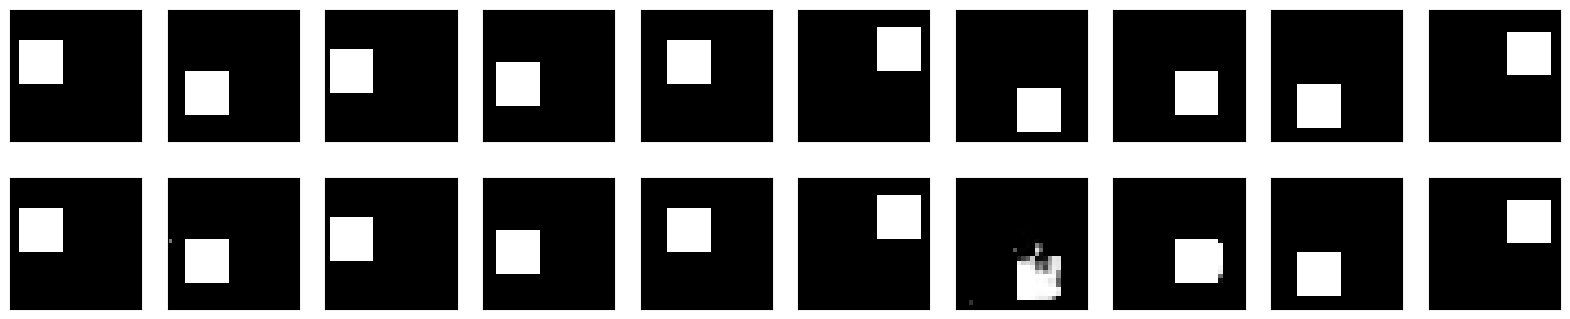

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0028 - val_loss: 0.0379
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 5.8470e-04 - val_loss: 0.0143
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 1.5766e-04 - val_loss: 0.0208
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 4.0865e-05 - val_loss: 0.0166
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 2.2087e-05 - val_loss: 0.0176
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 1.2950e-05 - val_loss: 0.0162
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 9.5446e-06 - val_loss: 0.0166
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 7.1400e-06 - val_loss: 0.0166
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 5.7941e-06 - val_loss: 0.0164
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 4.8623e-06 - val_loss: 0.0166
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


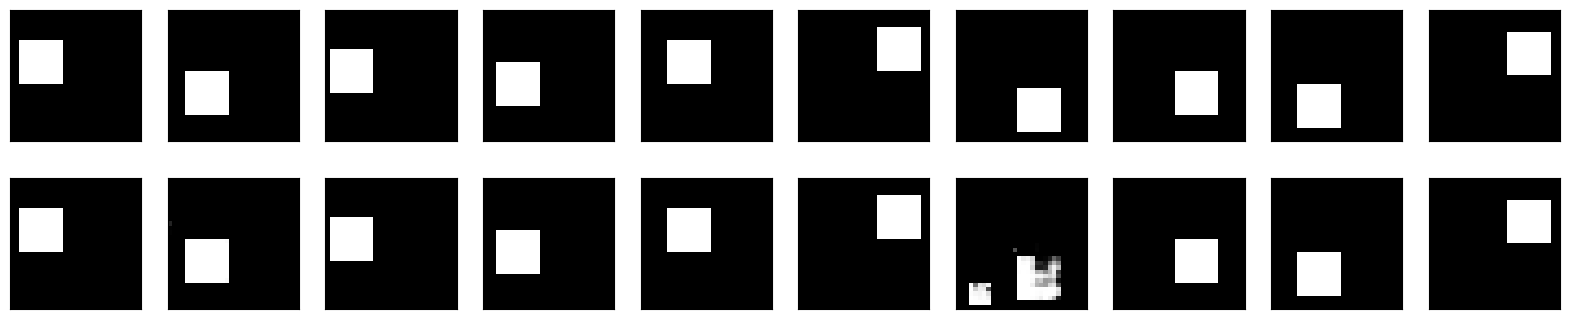

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0021 - val_loss: 0.0135
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 6.0234e-04 - val_loss: 8.3234e-04
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 1.1110e-04 - val_loss: 0.0012
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 4.5077e-05 - val_loss: 0.0015
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 2.2555e-05 - val_loss: 0.0014
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 1.3828e-05 - val_loss: 0.0013
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 9.9933e-06 - val_loss: 0.0012
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 7.6904e-06 - val_loss: 0.0012
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 6.1024e-06 - val_loss: 0.0012
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 4.8781e-06 - val_loss: 0.0011
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


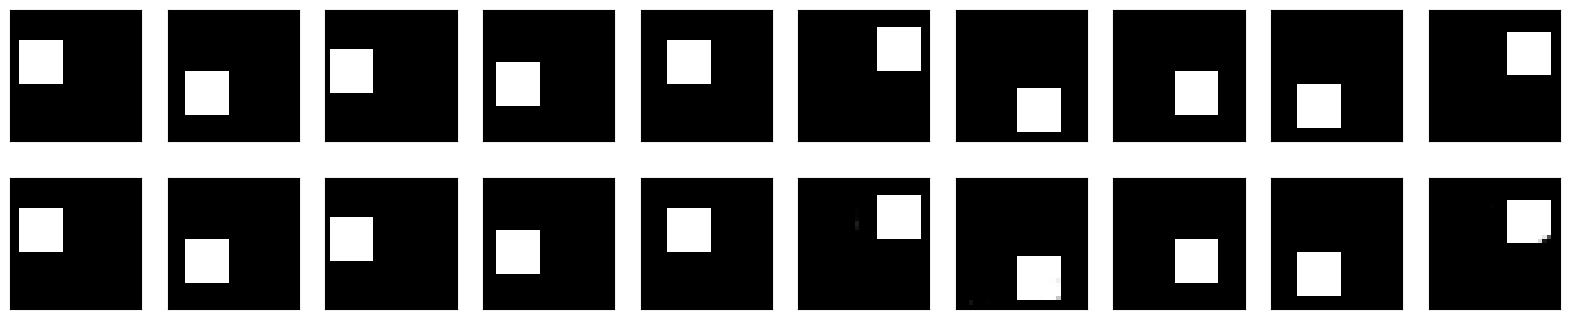

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 9.6530e-04 - val_loss: 0.0031
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 2.6666e-04 - val_loss: 1.1539e-04
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 7.4358e-05 - val_loss: 1.2996e-04
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 3.5392e-05 - val_loss: 9.7841e-05
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 1.4204e-05 - val_loss: 7.7667e-05
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 9.4668e-06 - val_loss: 7.1478e-05
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 6.8867e-06 - val_loss: 6.1376e-05
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 5.2230e-06 - val_loss: 5.1903e-05
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 4.1569e-06 - val_loss: 4.1757e-05
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 3.4302e-06 - val_loss: 3.9406e-05
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


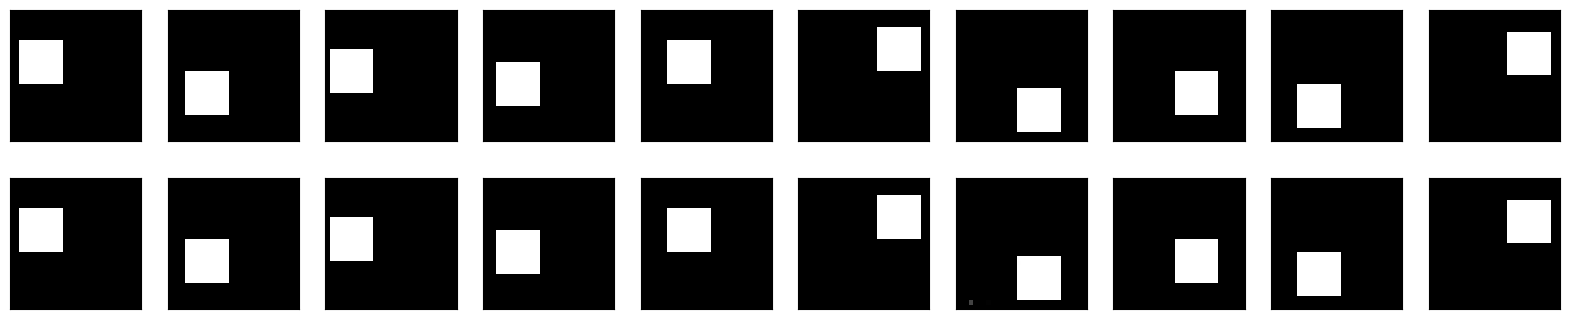

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.0048 - val_loss: 0.0120
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0018 - val_loss: 0.0507
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 3.5387e-04 - val_loss: 0.0159
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 1.0926e-04 - val_loss: 0.0154
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 5.5223e-05 - val_loss: 0.0148
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 2.8810e-05 - val_loss: 0.0159
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 2.0367e-05 - val_loss: 0.0164
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 1.5125e-05 - val_loss: 0.0168
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.1578e-05 - val_loss: 0.0168
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 9.5740e-06 - val_loss: 0.0177
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


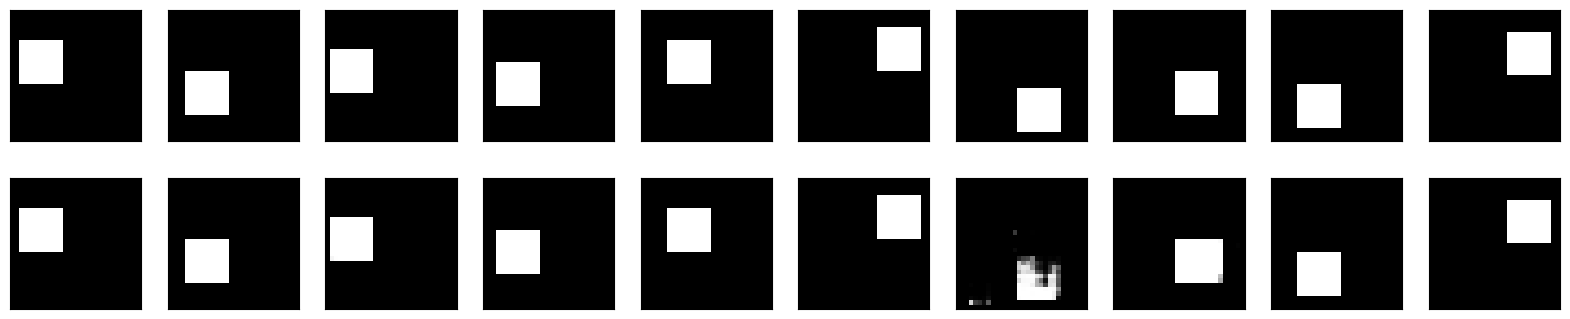

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 0.0016 - val_loss: 0.0205
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0024 - val_loss: 0.0517
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 4.4059e-04 - val_loss: 0.0105
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.2308e-04 - val_loss: 0.0101
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 5.9285e-05 - val_loss: 0.0108
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 3.5236e-05 - val_loss: 0.0112
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 2.3797e-05 - val_loss: 0.0112
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 1.8159e-05 - val_loss: 0.0115
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.4557e-05 - val_loss: 0.0117
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 1.2024e-05 - val_loss: 0.0120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


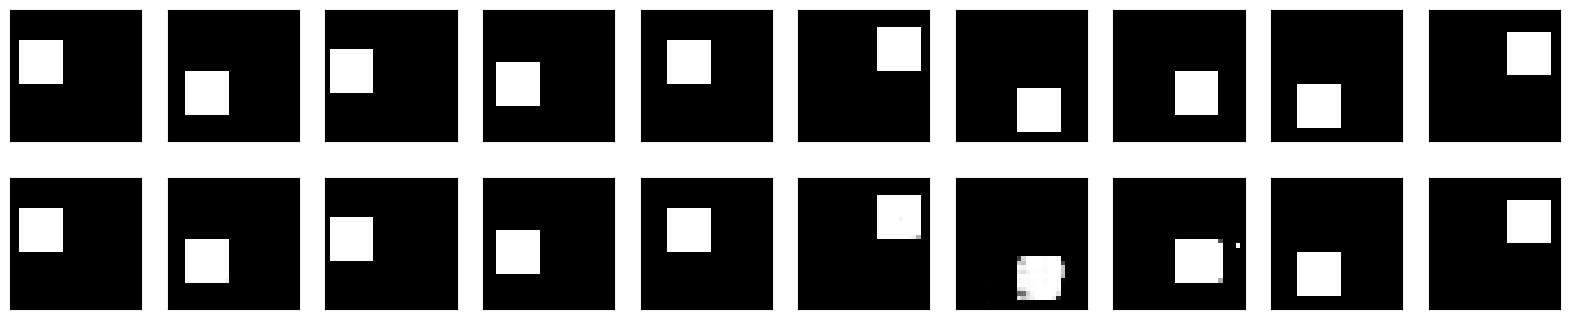

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 4.6863e-04 - val_loss: 0.0025
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 1.3501e-04 - val_loss: 6.2468e-04
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 5.0134e-05 - val_loss: 0.0012
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 3.8965e-05 - val_loss: 0.0020
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 2.5687e-05 - val_loss: 0.0032
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 1.9013e-05 - val_loss: 0.0031
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 1.6246e-05 - val_loss: 0.0028
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 1.3390e-05 - val_loss: 0.0028
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 1.1727e-05 - val_loss: 0.0029
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 1.0888e-05 - val_loss: 0.0028
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


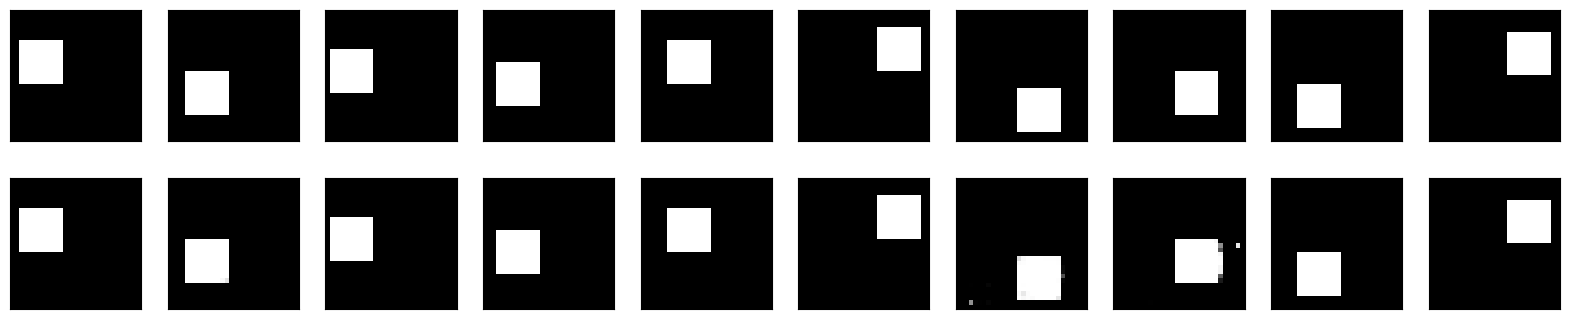

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 6.6536e-04 - val_loss: 0.0037
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 2.1042e-04 - val_loss: 0.0062
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 6.4433e-05 - val_loss: 0.0039
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 3.7341e-05 - val_loss: 0.0036
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 1.9190e-05 - val_loss: 0.0038
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 1.0317e-05 - val_loss: 0.0041
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 7.8999e-06 - val_loss: 0.0041
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 6.2146e-06 - val_loss: 0.0042
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 5.2327e-06 - val_loss: 0.0044
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 4.5064e-06 - val_loss: 0.0045
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


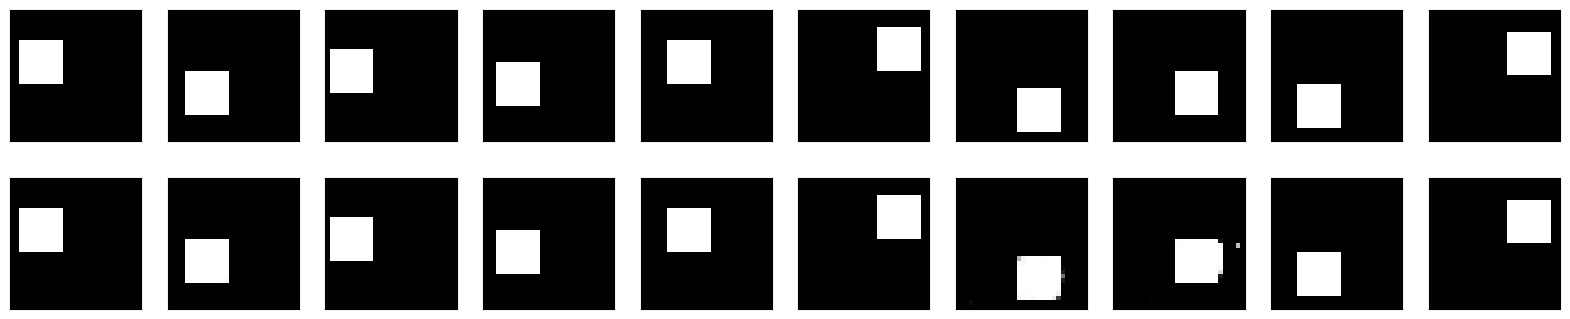

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0030 - val_loss: 0.2109
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 4.1885e-04 - val_loss: 0.3464
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 1.2709e-04 - val_loss: 0.2838
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 5.5778e-05 - val_loss: 0.2620
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 3.0608e-05 - val_loss: 0.2671
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 2.4050e-05 - val_loss: 0.2715
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 2.0088e-05 - val_loss: 0.2705
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.7211e-05 - val_loss: 0.2709
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.5230e-05 - val_loss: 0.2711
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 1.4224e-05 - val_loss: 0.2635
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


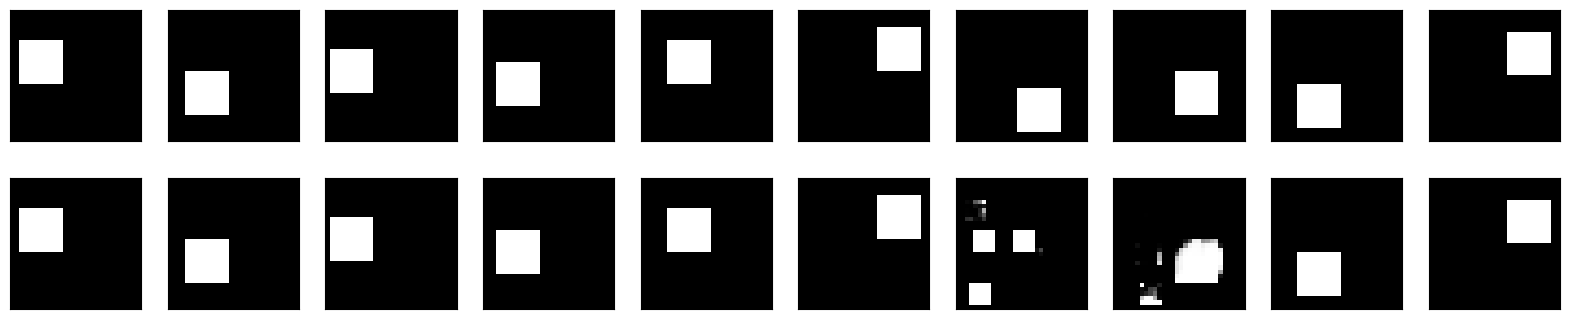

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.0027 - val_loss: 0.2143
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 8.3939e-04 - val_loss: 0.0208
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 2.4773e-04 - val_loss: 0.0667
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 1.2857e-04 - val_loss: 0.0935
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 7.8369e-05 - val_loss: 0.0887
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 6.1424e-05 - val_loss: 0.0913
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 4.9845e-05 - val_loss: 0.0931
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 3.8827e-05 - val_loss: 0.1136
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 3.4439e-05 - val_loss: 0.0953
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 2.6230e-05 - val_loss: 0.1022
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


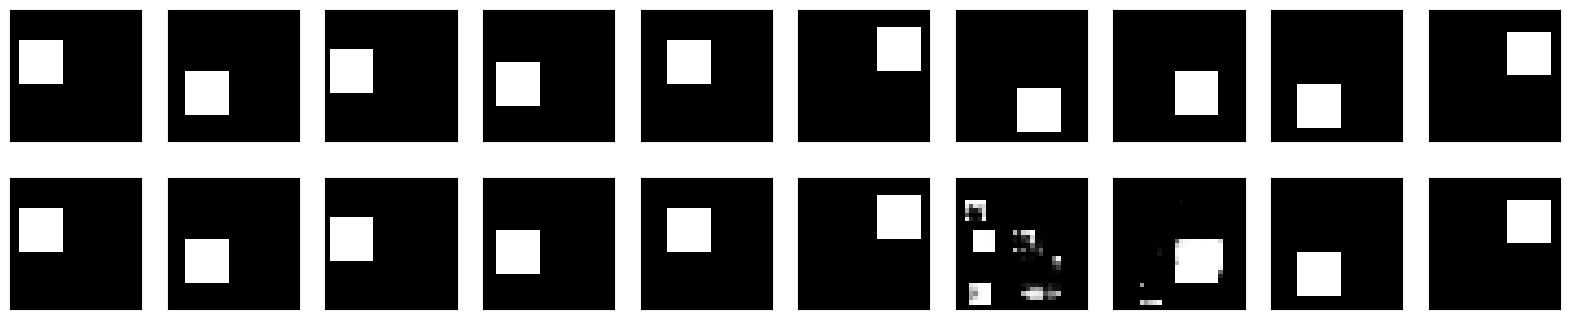

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0013 - val_loss: 0.0543
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 2.2888e-04 - val_loss: 0.1441
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 4.9343e-05 - val_loss: 0.1044
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 2.5463e-05 - val_loss: 0.1076
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.5403e-05 - val_loss: 0.1007
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 1.0826e-05 - val_loss: 0.0987
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 8.3392e-06 - val_loss: 0.1003
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 6.5541e-06 - val_loss: 0.0952
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 5.4378e-06 - val_loss: 0.0949
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 4.6192e-06 - val_loss: 0.0938
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


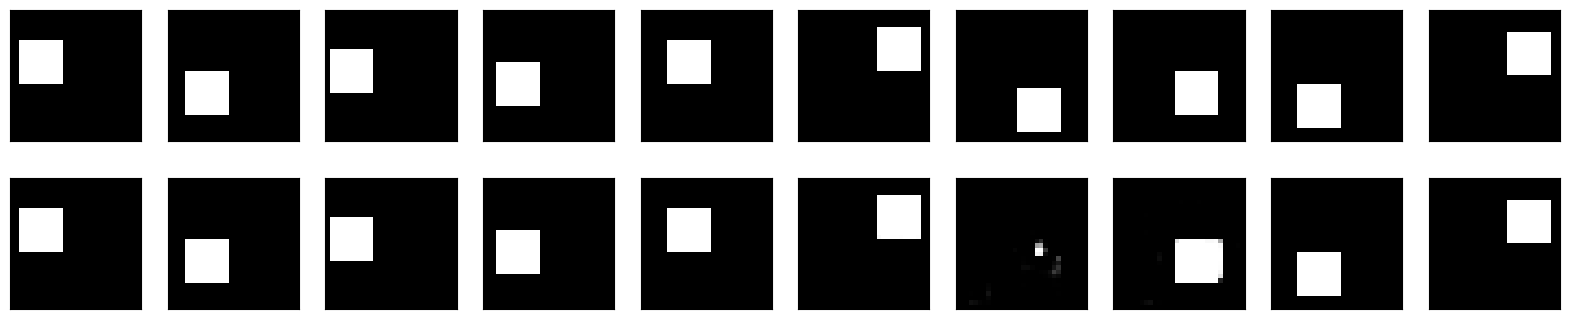

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 3.4963e-04 - val_loss: 0.0506
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 1.7784e-04 - val_loss: 0.2515
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 9.7748e-05 - val_loss: 0.2411
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 2.8904e-05 - val_loss: 0.2374
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 1.3804e-05 - val_loss: 0.2511
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 7.8926e-06 - val_loss: 0.2502
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 5.8688e-06 - val_loss: 0.2532
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 4.5616e-06 - val_loss: 0.2558
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 3.7246e-06 - val_loss: 0.2578
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 3.2062e-06 - val_loss: 0.2591
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


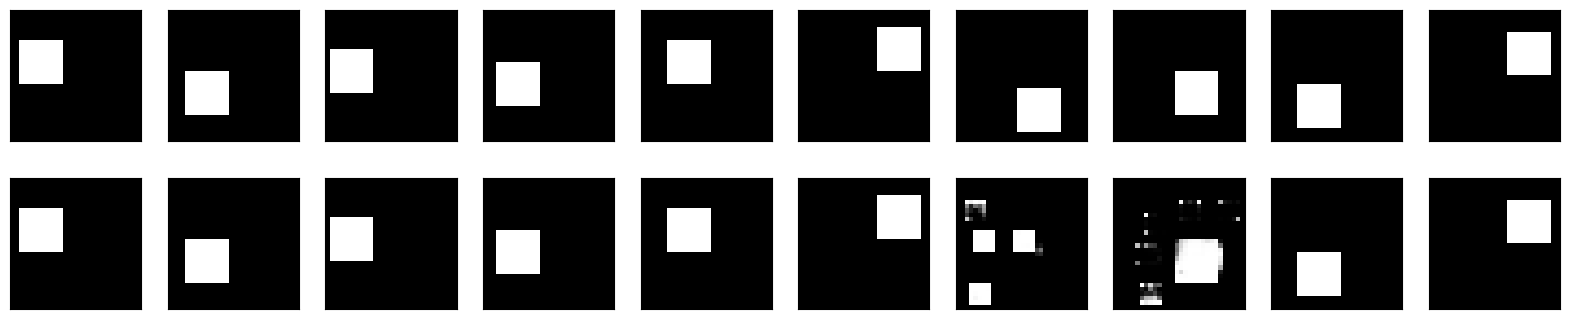

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.0054 - val_loss: 0.2265
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 7.8243e-04 - val_loss: 0.1920
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.6441e-04 - val_loss: 0.1698
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 4.0512e-05 - val_loss: 0.1953
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 2.1835e-05 - val_loss: 0.2053
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.4833e-05 - val_loss: 0.2046
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.1079e-05 - val_loss: 0.2029
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 8.8984e-06 - val_loss: 0.2065
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 7.3497e-06 - val_loss: 0.2066
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 6.2435e-06 - val_loss: 0.2080
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


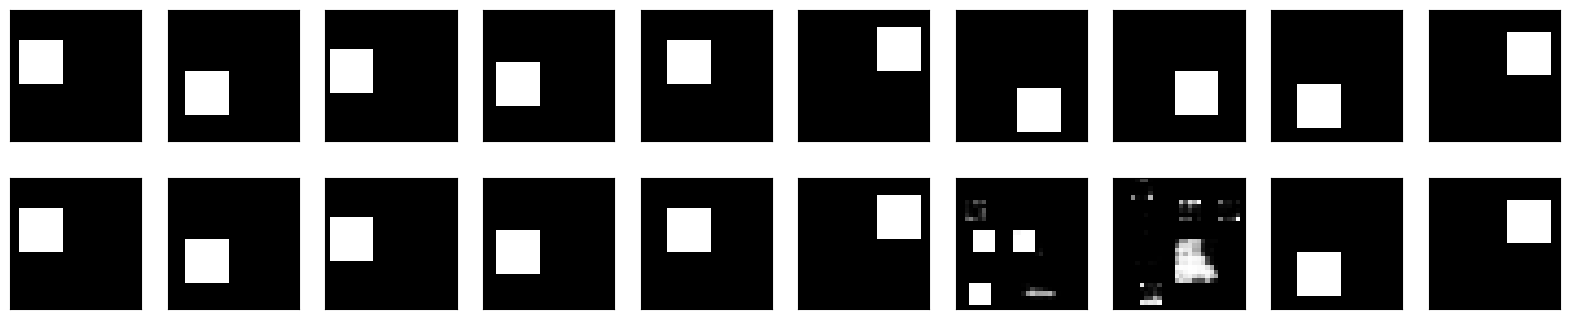

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0021 - val_loss: 0.0197
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0010 - val_loss: 0.0564
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 2.2671e-04 - val_loss: 0.0337
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 1.0723e-04 - val_loss: 0.0482
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 4.8815e-05 - val_loss: 0.0730
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 2.9103e-05 - val_loss: 0.0772
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 2.0593e-05 - val_loss: 0.0836
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 1.6555e-05 - val_loss: 0.0859
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 1.4039e-05 - val_loss: 0.0886
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 1.0850e-05 - val_loss: 0.0916
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


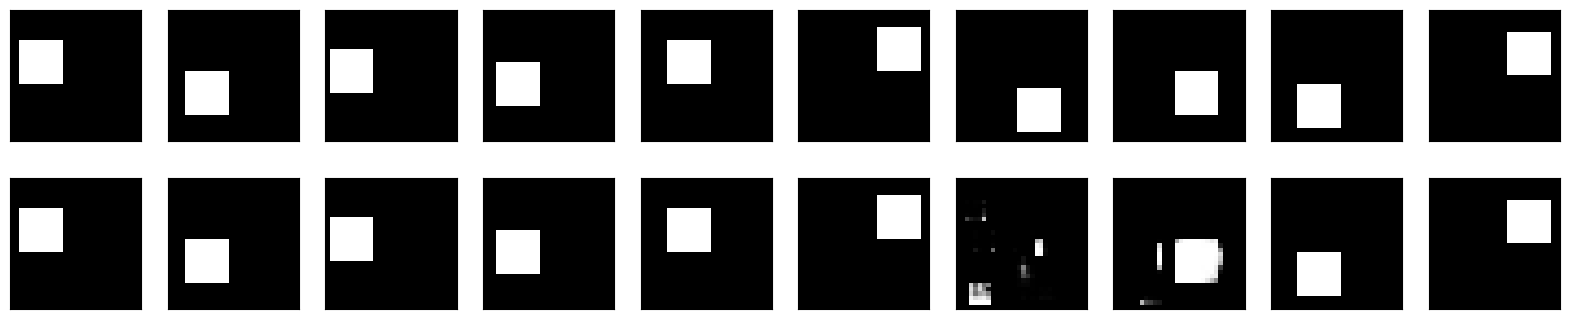

In [55]:
for _ in range(20):
    train_in_list, train_out_list = build_training()
    train_in = np.array(train_in_list)
    train_out = np.array(train_out_list)

    autoencoder.fit(
        x=train_in,
        y=train_out,
        epochs=10,
        batch_size=50,
        shuffle=True,
        validation_data=(test_in, test_out),
    )

    predictions = autoencoder.predict(test_in)
    display(test_out, predictions)

In [52]:
def compress(a):
    b = np.zeros((max_dim,max_dim))
    for x in range(max_dim):
        for y in range(max_dim):
            for c in range(max_color+1):
                if a[x][y][c]:
                    b[x][y] = c
    return b

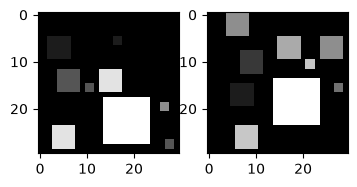

In [53]:
figure = plt.figure(figsize=(4,2))
col, row = 2, 1
figure.add_subplot(row, col, 1)
plt.imshow(compress(test_in[6]),cmap='gray')
figure.add_subplot(row, col, 2)
plt.imshow(compress(test_in[7]),cmap='gray')
plt.show()

In [59]:
autoencoder.save("./model_1_261108.keras")